# Creating and Evaluating Survivor Predictor on Titanic Dataset

## Loading and inspecting data

In [2]:
import numpy as np
import pandas as pd

df_raw_train = pd.read_csv("data/titanic/train.csv")
df_raw_test = pd.read_csv("data/titanic/test.csv")

In [3]:
df_raw_train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
df_raw_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [5]:
df_raw_train["Survived"].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [6]:
df_raw_train["Sex"].value_counts()

Sex
male      577
female    314
Name: count, dtype: int64

In [7]:
df_raw_train["Pclass"].value_counts()

Pclass
3    491
1    216
2    184
Name: count, dtype: int64

In [8]:
df_raw_train["SibSp"].value_counts()

SibSp
0    608
1    209
2     28
4     18
3     16
8      7
5      5
Name: count, dtype: int64

In [23]:
df_raw_train["Cabin"].value_counts()

Cabin
B96 B98        691
G6               4
C23 C25 C27      4
F33              3
E101             3
              ... 
E17              1
A24              1
C50              1
B42              1
C148             1
Name: count, Length: 147, dtype: int64

In [10]:
df_raw_train.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

## Cleaning

In [14]:
ageAvg = df_raw_train["Age"].mean()
print(ageAvg)
print(df_raw_train["Cabin"].mode())

29.699113025210085
0        B96 B98
1    C23 C25 C27
2             G6
Name: Cabin, dtype: str


In [16]:
df_raw_train["Embarked"].value_counts()

Embarked
S    644
C    168
Q     77
Name: count, dtype: int64

In [20]:
df_train_cleaned = df_raw_train
df_train_cleaned["Age"] = df_train_cleaned["Age"].fillna( value=df_train_cleaned["Age"].mean())
df_train_cleaned["Cabin"] = df_train_cleaned["Cabin"].fillna(value=df_train_cleaned["Cabin"].mode()[0])
df_train_cleaned["Embarked"] = df_train_cleaned["Embarked"].fillna(value=df_train_cleaned["Embarked"].mode()[0])

df_train_cleaned.isna().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
dtype: int64

## Splitting

In [38]:
x_train = df_train_cleaned.drop(columns=["Survived"])
y_train = df_train_cleaned["Survived"]

x_train.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,B96 B98,S
1,2,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,B96 B98,S
3,4,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,B96 B98,S


## Visualization

[]

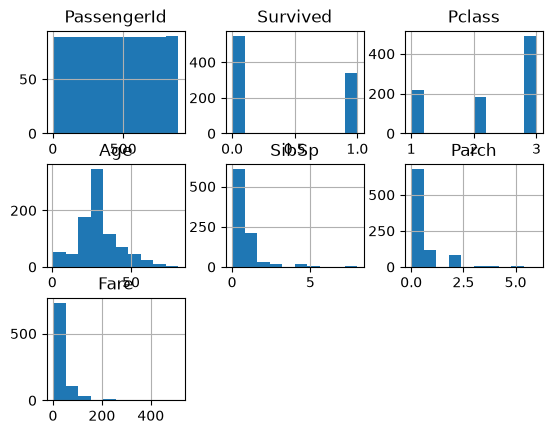

In [21]:
import matplotlib.pyplot as plt

df_train_cleaned.hist()
plt.plot()

[]

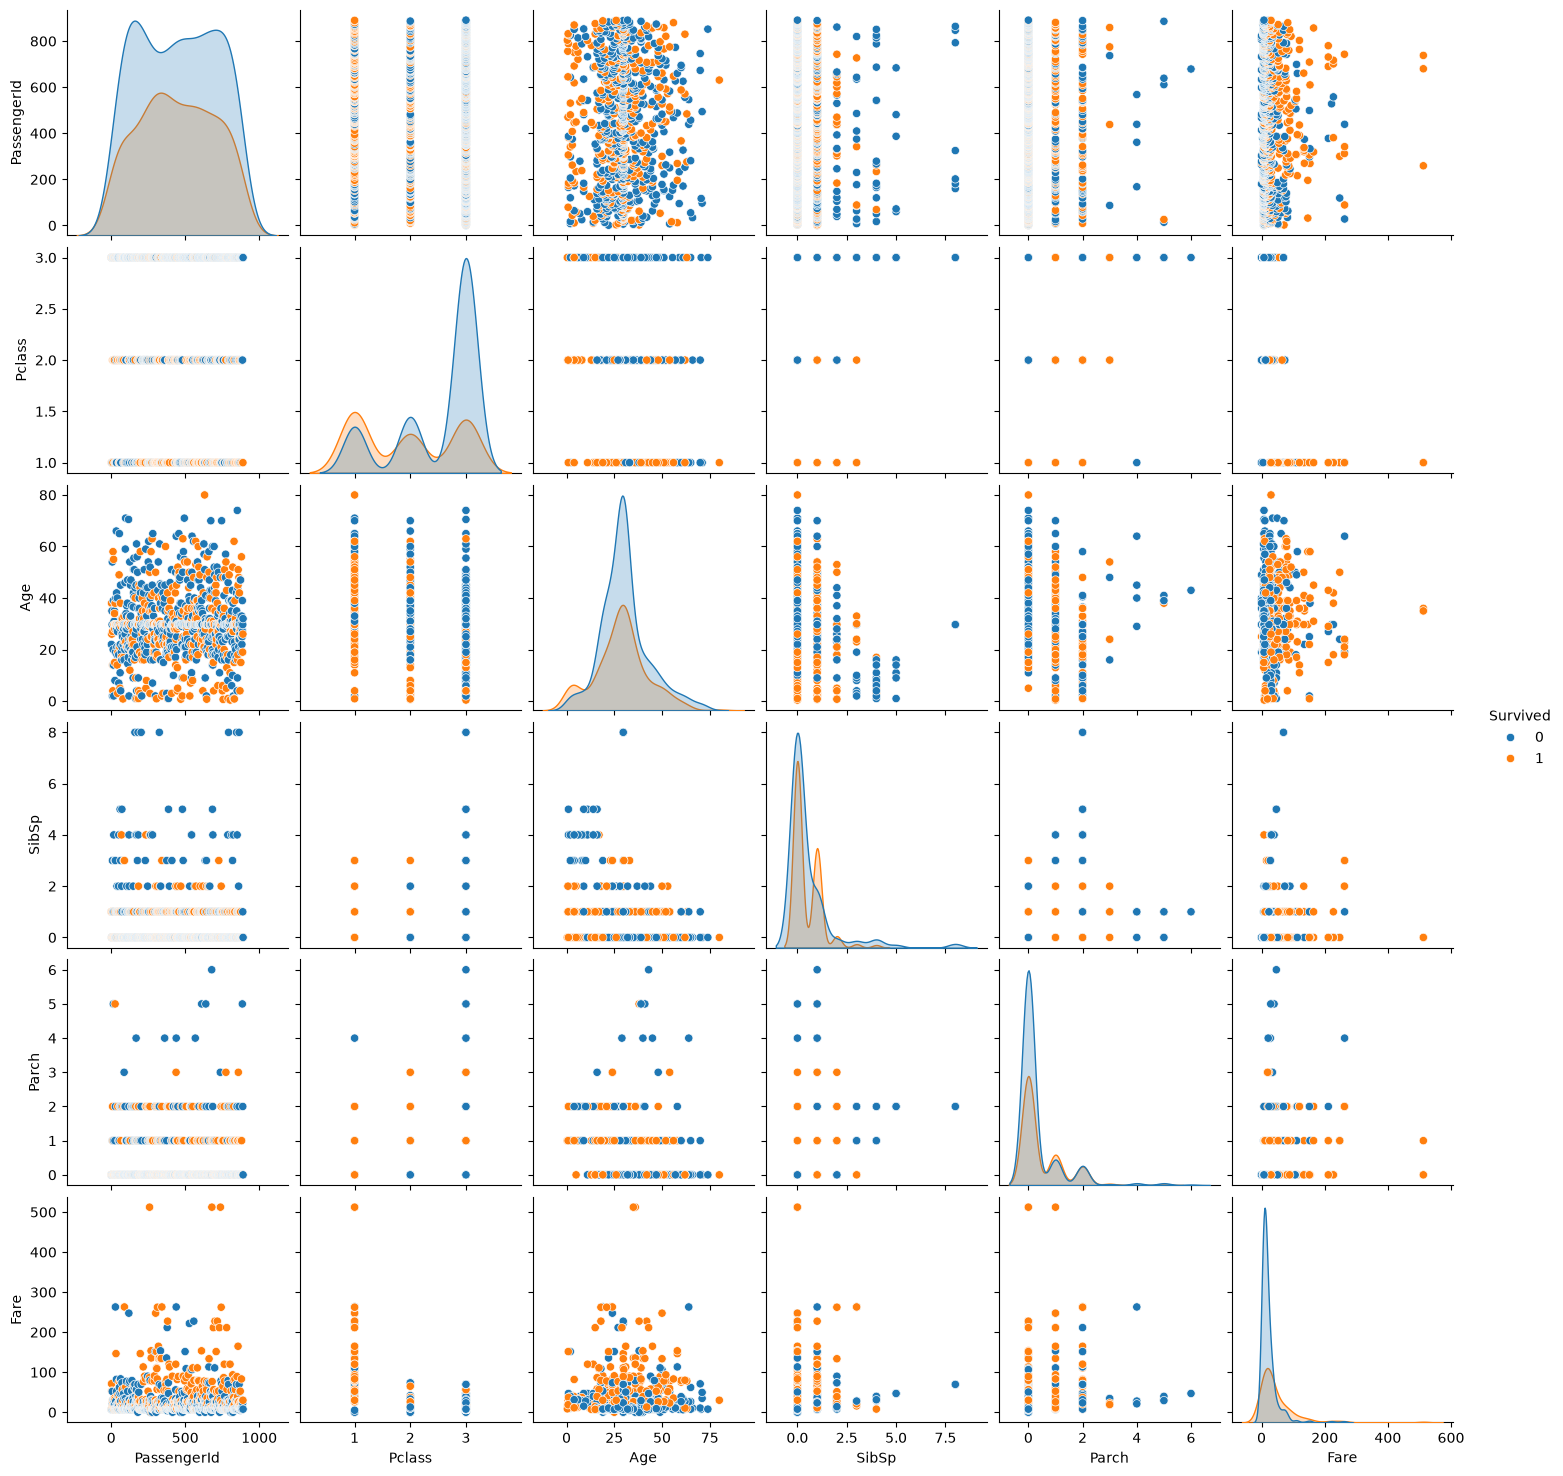

In [24]:
import seaborn as sns

sns.pairplot(df_train_cleaned, hue="Survived" )
plt.plot()


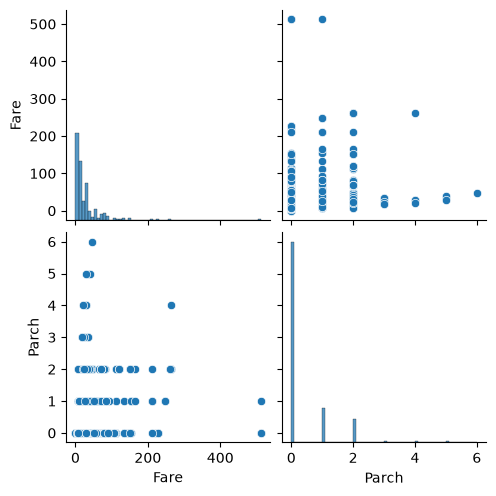

In [28]:
sns.pairplot(df_train_cleaned[["Fare", "Parch"]], )

<Axes: xlabel='Survived', ylabel='Age'>

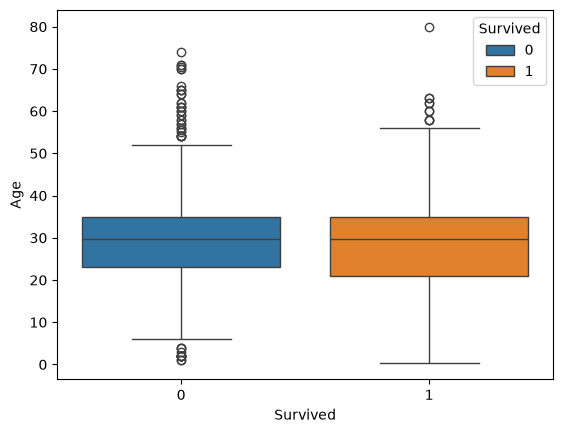

In [29]:
sns.boxplot(df_train_cleaned, x="Survived", y="Age", hue="Survived")

<Axes: xlabel='Age', ylabel='Density'>

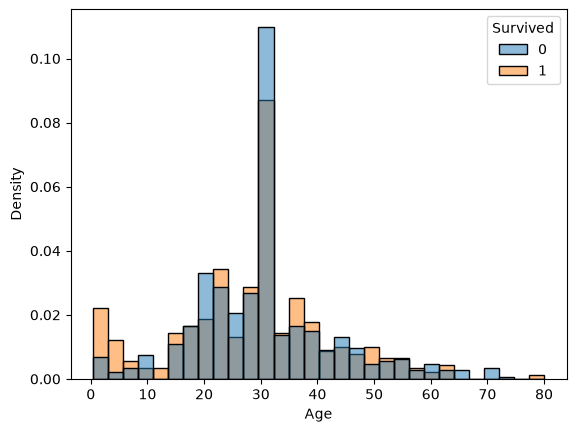

In [31]:
sns.histplot(data=df_train_cleaned, x="Age", stat="density", common_norm=False, hue="Survived")

<Axes: xlabel='Pclass', ylabel='Density'>

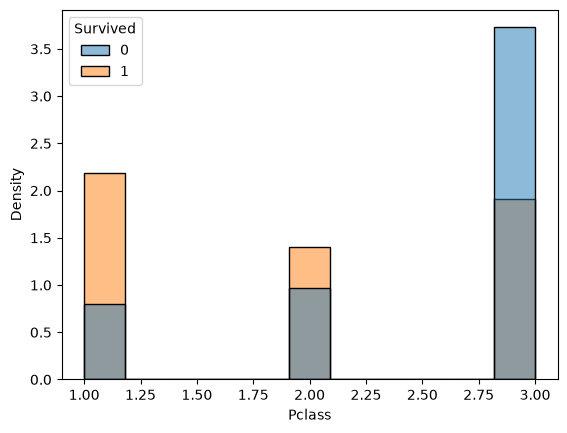

In [32]:
sns.histplot(data=df_train_cleaned, x="Pclass", stat="density", common_norm=False, hue="Survived")

<Axes: xlabel='SibSp', ylabel='Density'>

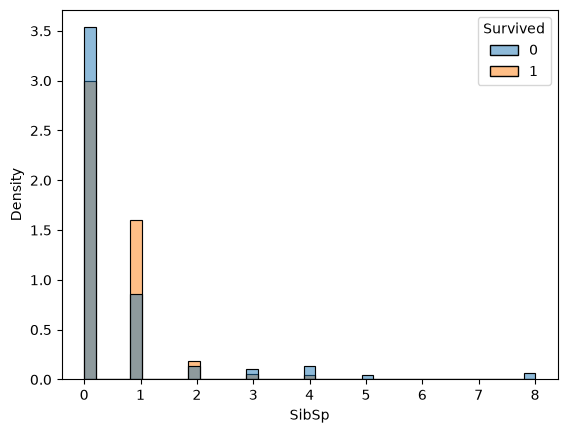

In [33]:
sns.histplot(data=df_train_cleaned, x="SibSp", stat="density", common_norm=False, hue="Survived")

<Axes: xlabel='PassengerId', ylabel='Density'>

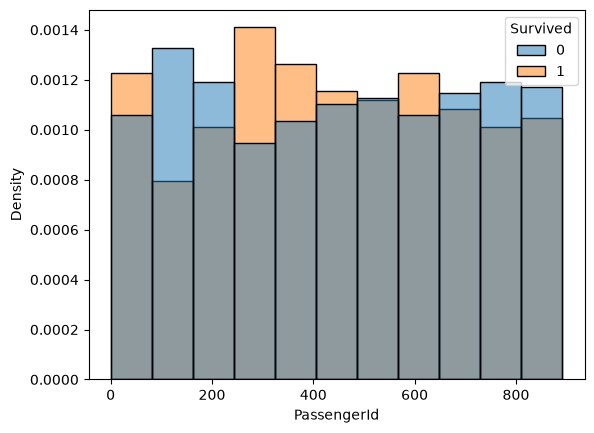

In [35]:
sns.histplot(data=df_train_cleaned, x="PassengerId", stat="density", common_norm=False, hue="Survived")

<Axes: xlabel='Embarked'>

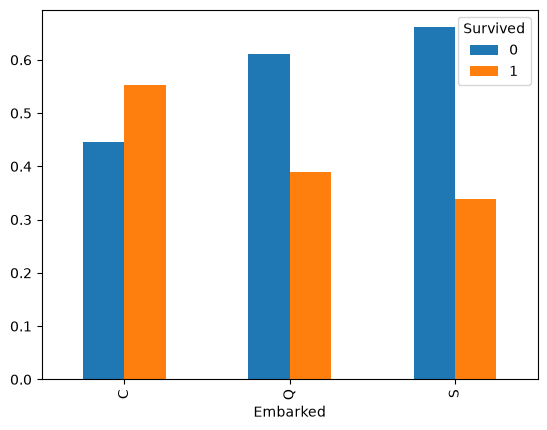

In [36]:
pd.crosstab(df_train_cleaned["Embarked"], df_train_cleaned["Survived"], normalize="index").plot(kind="bar")

## Model Training

### Preprocessing Pipeline

In [39]:
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier


num_pipeline = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
char_pipeline = make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder() )

knn = KNeighborsClassifier(n_neighbors=5, weights="distance")

preprocessing = ColumnTransformer([("numpipeline", num_pipeline, ["Pclass", "Age", "SibSp", "Parch", "Fare"]),
                           ("charpipeline", char_pipeline, ["Sex", "Embarked"])],)



### KNN Classifier

In [40]:
final_model = Pipeline([("preprocessing", preprocessing ), ("knn", knn)])

              precision    recall  f1-score   support

           0       0.82      0.84      0.83       549
           1       0.73      0.71      0.72       342

    accuracy                           0.79       891
   macro avg       0.78      0.78      0.78       891
weighted avg       0.79      0.79      0.79       891



[]

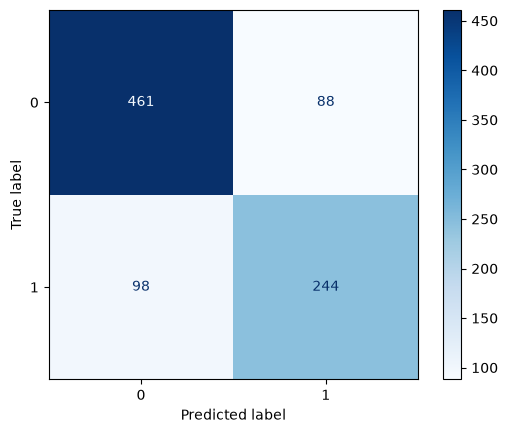

In [42]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

pred = cross_val_predict(final_model, x_train, y_train)

cr = classification_report(y_train, pred)
print(cr)

ConfusionMatrixDisplay.from_predictions(y_train, pred, cmap="Blues")
plt.plot()

### Logistic Regression

In [45]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression()

final_model = Pipeline([("preprocessing", preprocessing ), ("lr", lr)])

              precision    recall  f1-score   support

           0       0.82      0.84      0.83       549
           1       0.73      0.70      0.71       342

    accuracy                           0.79       891
   macro avg       0.78      0.77      0.77       891
weighted avg       0.79      0.79      0.79       891



[]

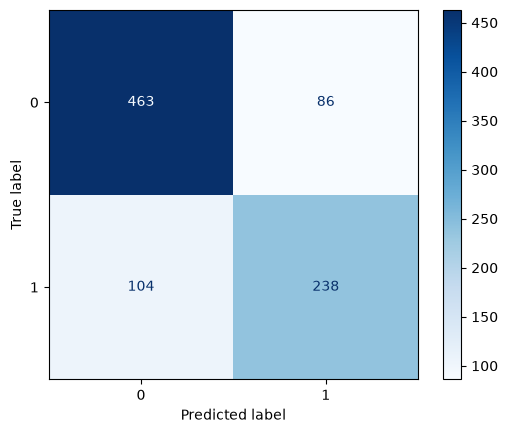

In [46]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

pred = cross_val_predict(final_model, x_train, y_train)

cr = classification_report(y_train, pred)
print(cr)

ConfusionMatrixDisplay.from_predictions(y_train, pred, cmap="Blues")
plt.plot()

### Random Forest Classifier

In [47]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier()

final_model = Pipeline([("preprocessing", preprocessing ), ("rf", rf)])

              precision    recall  f1-score   support

           0       0.83      0.86      0.85       549
           1       0.76      0.72      0.74       342

    accuracy                           0.81       891
   macro avg       0.80      0.79      0.79       891
weighted avg       0.81      0.81      0.81       891



[]

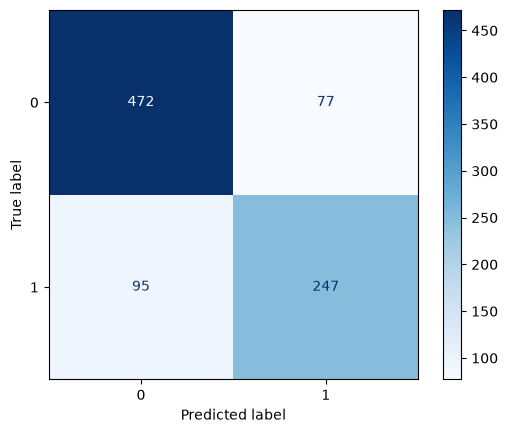

In [48]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

pred = cross_val_predict(final_model, x_train, y_train)

cr = classification_report(y_train, pred)
print(cr)

ConfusionMatrixDisplay.from_predictions(y_train, pred, cmap="Blues")
plt.plot()

## Hyperparameter Tuning on Random Forest

In [52]:
from sklearn.model_selection import GridSearchCV

grid = {
    "rf__n_estimators": [100, 200, 300, 500, 800],
    "rf__criterion": ["gini", "entropy", "log_loss"],
    "rf__max_depth": [10,20,30]
    
}

gs = GridSearchCV(final_model, grid, scoring="f1", verbose=1)

gs.fit(x_train, y_train)

print(gs.best_params_)
print(gs.best_score_)

Fitting 5 folds for each of 45 candidates, totalling 225 fits
{'rf__criterion': 'gini', 'rf__max_depth': 10, 'rf__n_estimators': 500}
0.7621468308907948


In [53]:
rf = RandomForestClassifier(criterion="gini", max_depth=10, n_estimators=500)

final_model = Pipeline([("preprocessing", preprocessing ), ("rf", rf)])

              precision    recall  f1-score   support

           0       0.84      0.89      0.87       549
           1       0.81      0.72      0.76       342

    accuracy                           0.83       891
   macro avg       0.82      0.81      0.81       891
weighted avg       0.83      0.83      0.83       891



[]

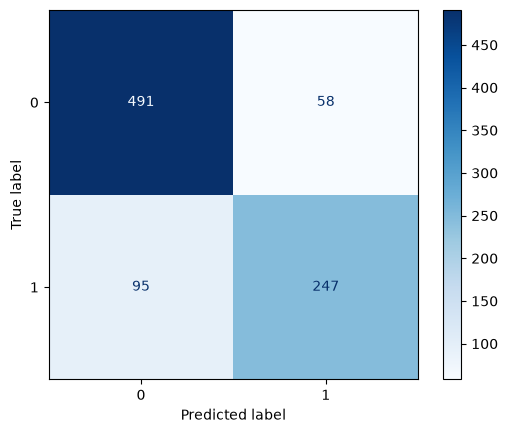

In [54]:

pred = cross_val_predict(final_model, x_train, y_train)

cr = classification_report(y_train, pred)
print(cr)

ConfusionMatrixDisplay.from_predictions(y_train, pred, cmap="Blues")
plt.plot()